<a href="https://colab.research.google.com/github/SaronJenish/CSA4703---Deep-Learning/blob/main/Experiment_02_Covariance_Eigenvalues_and_Eigenvectors.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment 2: Covariance, Eigenvalues and Eigenvectors

CSA47 – Deep Learning. Run the setup cell first, then execute the experiment cells in order.


In [1]:
# Common setup – run this cell first
import os, time, warnings, math
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, mean_absolute_error, mean_squared_error)
np.random.seed(42)
plt.rcParams["figure.figsize"] = (7, 4)
print("Setup complete")

Setup complete


## Experiment 2 – Covariance, Eigenvalues and Eigenvectors

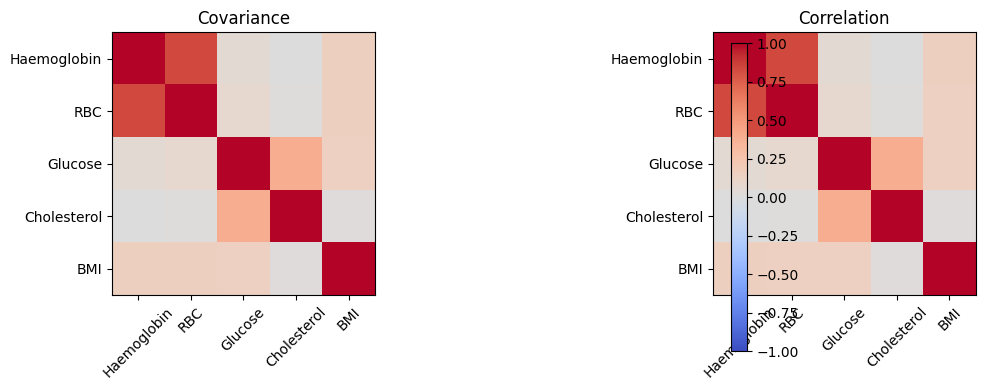

Eigenvalues: [1.91019775 1.40132678 0.95168047 0.59131399 0.17060664]
Variance (%): [38.01 27.89 18.94 11.77  3.4 ]


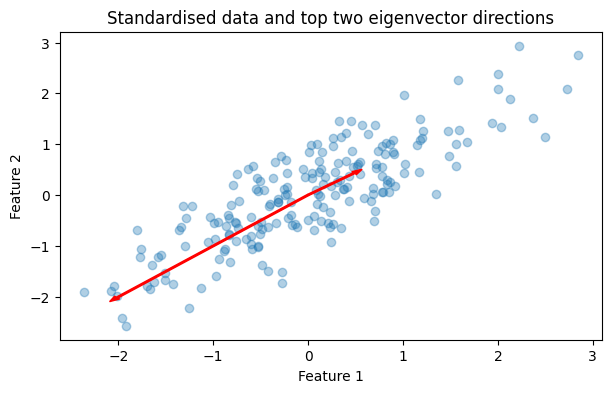

In [2]:
# Synthetic 200-patient dataset
n=200
base=np.random.normal(size=(n,5))
data=pd.DataFrame({
    "Haemoglobin":14+1.2*base[:,0],
    "RBC":5+0.5*base[:,0]+0.3*base[:,1],
    "Glucose":100+15*base[:,2],
    "Cholesterol":190+25*(0.4*base[:,2]+base[:,3]),
    "BMI":25+4*(0.2*base[:,0]+base[:,4])
})
X=StandardScaler().fit_transform(data)
cov=np.cov(X,rowvar=False); corr=np.corrcoef(X,rowvar=False)
fig,ax=plt.subplots(1,2,figsize=(12,4))
for a,m,t in zip(ax,[cov,corr],["Covariance","Correlation"]):
    im=a.imshow(m,cmap="coolwarm",vmin=-1,vmax=1); a.set_title(t); a.set_xticks(range(5),data.columns,rotation=45); a.set_yticks(range(5),data.columns)
plt.colorbar(im,ax=ax); plt.tight_layout(); plt.show()
vals,vecs=np.linalg.eigh(cov); order=np.argsort(vals)[::-1]; vals,vecs=vals[order],vecs[:,order]
ratio=vals/vals.sum()
print("Eigenvalues:",vals); print("Variance (%):",np.round(ratio*100,2))
plt.scatter(X[:,0],X[:,1],alpha=.35)
scale=3
for k in range(2):
    plt.arrow(0,0,vecs[0,k]*scale,vecs[1,k]*scale,width=.025,color="red")
plt.title("Standardised data and top two eigenvector directions"); plt.xlabel("Feature 1"); plt.ylabel("Feature 2"); plt.show()